<a href="https://colab.research.google.com/github/akshu88/Applied-ML-Lab/blob/main/Exp_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Simple Linear Regression: House Price Prediction

This notebook walks through a complete, simple pipeline to predict house **price** from house **area** using Linear Regression.

Steps covered:
1. Import libraries & data
2. Basic data preprocessing
3. Visualize data (scatter plot)
4. Train/test split
5. Train Linear Regression model
6. Slope & intercept
7. Accuracy metrics
8. Visualize the regression line
9. Predict price for new input

This notebook expects `Housing.csv` with exactly two columns: `area` (numeric) and `price` (numeric).

## 1. Import Libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')

## 2. Import Data

Run the **code cell right below**. It will show an **upload button** — click it and choose your `Housing.csv` file. Once uploaded, it loads automatically and shows a preview.

In [ ]:
# RUN THIS CELL: click "Choose Files" below and select Housing.csv
from google.colab import files
uploaded = files.upload()
CSV_PATH = list(uploaded.keys())[0]

df = pd.read_csv(CSV_PATH)
print('Shape:', df.shape)
df.head()

Saving Housing.csv to Housing.csv
Shape: (545, 2)


,area,price
0,7420,13300000
1,8960,12250000
2,9960,12250000
3,7500,12215000
4,7420,11410000


### Alternative: load from Google Drive instead

Only run this if you'd rather keep `Housing.csv` in your Drive instead of re-uploading it every session. Skip this if you already loaded the file above.

In [ ]:
# from google.colab import drive
# drive.mount('/content/drive')
# CSV_PATH = '/content/drive/MyDrive/Housing.csv'  # adjust to your actual path
# df = pd.read_csv(CSV_PATH)
# print('Shape:', df.shape)
# df.head()

## 3. Basic Data Preprocessing

For a *simple* linear regression we only use one feature (`area`) to predict the target (`price`), so we deliberately skip any feature engineering/selection beyond picking these two columns. We do:
- Check data types & missing values
- Drop rows with missing/invalid values
- Remove duplicate rows
- Make sure both columns are numeric

In [ ]:
FEATURE_COL = 'area'
TARGET_COL = 'price'

print('Data types:')
print(df.dtypes)
print('\nMissing values per column:')
print(df.isnull().sum())
print('\nBasic statistics:')
print(df[[FEATURE_COL, TARGET_COL]].describe())

Data types:
area     int64
price    int64
dtype: object

Missing values per column:
area     0
price    0
dtype: int64

Basic statistics:
               area         price
count    545.000000  5.450000e+02
mean    5150.541284  4.766729e+06
std     2170.141023  1.870440e+06
min     1650.000000  1.750000e+06
25%     3600.000000  3.430000e+06
50%     4600.000000  4.340000e+06
75%     6360.000000  5.740000e+06
max    16200.000000  1.330000e+07


In [ ]:
data = df[[FEATURE_COL, TARGET_COL]].copy()

data[FEATURE_COL] = pd.to_numeric(data[FEATURE_COL], errors='coerce')
data[TARGET_COL] = pd.to_numeric(data[TARGET_COL], errors='coerce')

before = len(data)
data = data.dropna().drop_duplicates().reset_index(drop=True)
after = len(data)
print(f'Rows before cleaning: {before}, after cleaning: {after}')

data.head()

Rows before cleaning: 545, after cleaning: 532


,area,price
0,7420,13300000
1,8960,12250000
2,9960,12250000
3,7500,12215000
4,7420,11410000


## 4. Visualize the Data (Scatter Plot)

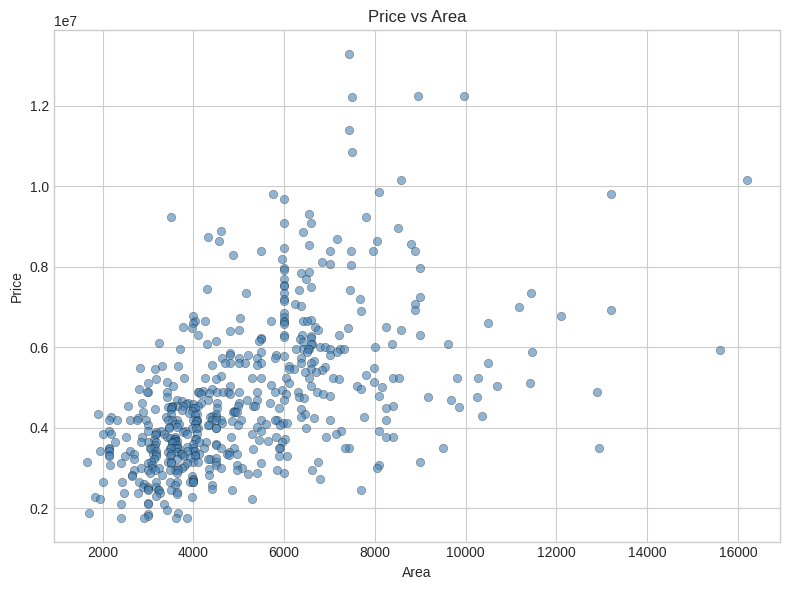

In [ ]:
plt.figure(figsize=(8, 6))
plt.scatter(data[FEATURE_COL], data[TARGET_COL], alpha=0.6, color='steelblue', edgecolor='k', linewidth=0.3)
plt.xlabel(FEATURE_COL.capitalize())
plt.ylabel(TARGET_COL.capitalize())
plt.title(f'{TARGET_COL.capitalize()} vs {FEATURE_COL.capitalize()}')
plt.tight_layout()
plt.show()

## 5. Train/Test Split

In [ ]:
X = data[[FEATURE_COL]].values
y = data[TARGET_COL].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Training samples:', X_train.shape[0])
print('Testing samples:', X_test.shape[0])

Training samples: 425
Testing samples: 107


## 6. Train the Linear Regression Model

In [ ]:
model = LinearRegression()
model.fit(X_train, y_train)

print('Model trained successfully!')

Model trained successfully!


## 7. Slope and Intercept

For a simple linear regression: `price = slope * area + intercept`

In [ ]:
slope = model.coef_[0]
intercept = model.intercept_

print(f'Slope (coefficient): {slope:.4f}')
print(f'Intercept: {intercept:.4f}')
print(f'\nEquation: price = {slope:.4f} * area + {intercept:.4f}')

Slope (coefficient): 441.5876
Intercept: 2450352.7349

Equation: price = 441.5876 * area + 2450352.7349


## 8. Accuracy Metrics

In [ ]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('Model Evaluation Metrics')
print('-' * 30)
print(f'Mean Absolute Error (MAE):  {mae:,.2f}')
print(f'Mean Squared Error (MSE):   {mse:,.2f}')
print(f'Root Mean Squared Error:    {rmse:,.2f}')
print(f'R-squared (R2 Score):       {r2:.4f}')

Model Evaluation Metrics
------------------------------
Mean Absolute Error (MAE):  1,424,905.44
Mean Squared Error (MSE):   3,547,685,936,845.33
Root Mean Squared Error:    1,883,530.18
R-squared (R2 Score):       0.2770


## 9. Visualize the Regression Line

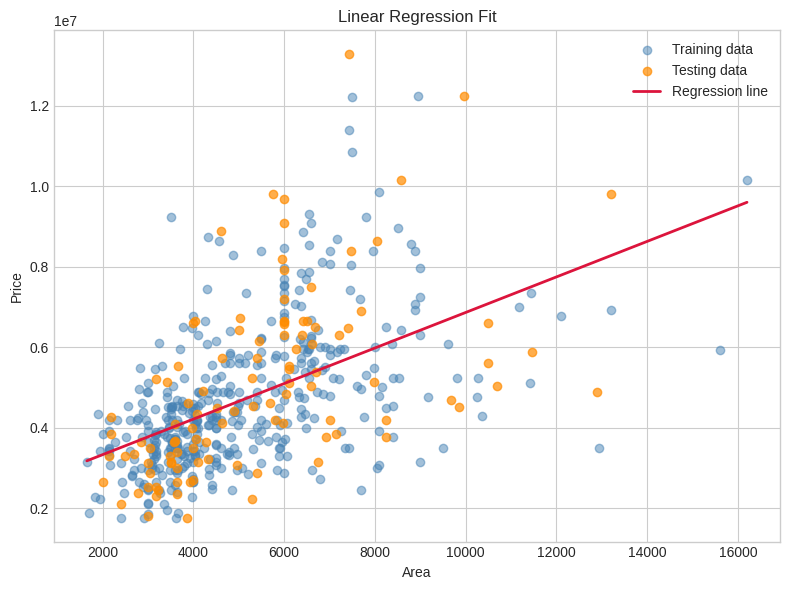

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(X_train, y_train, color='steelblue', alpha=0.5, label='Training data')
plt.scatter(X_test, y_test, color='darkorange', alpha=0.7, label='Testing data')

x_line = np.linspace(X.min(), X.max(), 100).reshape(-1, 1)
y_line = model.predict(x_line)
plt.plot(x_line, y_line, color='crimson', linewidth=2, label='Regression line')

plt.xlabel(FEATURE_COL.capitalize())
plt.ylabel(TARGET_COL.capitalize())
plt.title('Linear Regression Fit')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Predict on New Data

In [ ]:
def predict_price(area_value):
    """Predict house price given an area value (same units as training data)."""
    area_array = np.array([[area_value]])
    predicted_price = model.predict(area_array)[0]
    return predicted_price

example_area = 5000
predicted = predict_price(example_area)
print(f'Predicted price for area = {example_area}: {predicted:,.2f}')

new_areas = pd.DataFrame({FEATURE_COL: [3000, 5000, 7500, 10000]})
new_areas['predicted_price'] = model.predict(new_areas[[FEATURE_COL]])
new_areas

Predicted price for area = 5000: 4,658,290.72


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(


,area,predicted_price
0,3000,3.775116e+06
1,5000,4.658291e+06
2,7500,5.762260e+06
3,10000,6.866229e+06
